# 1.加载原图并展示

torch.Size([3, 256, 256])


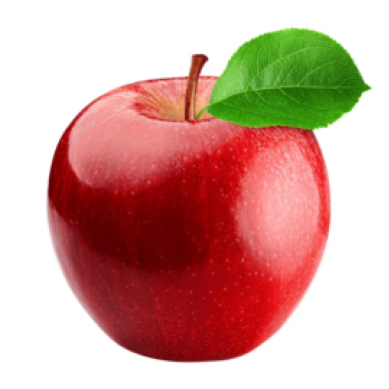

In [1]:
# 【初学者阅读说明】
# 这是 apple.ipynb 的第 2 个单元格，属于历史学习实验。
# Notebook 与 .py 不同：多个单元格共享内核变量，通常要按顺序运行前置单元格。
# 本次只增加注释，保留原实验行为和已有输出；正式项目的修正请以各包内 .py 为准。

# 导入 matplotlib.pyplot，把图片张量绘制成可查看的对比图；as plt 给它起较短别名
import matplotlib.pyplot as plt #用于图像显示
# 从 PIL 导入 Image，用于通过 Pillow 打开、转换和生成图片。
from PIL import Image #用于图像加载和处理
# 导入 torchvision.transforms，使用图像缩放与张量转换等视觉工具；as transforms 给它起较短别名
import torchvision.transforms as transforms #用于图像预处理

# 定义图像转换操作
# 旧苹果实验使用 256×256；Compose 按顺序缩放并转张量，与正式项目的 64×64 配置不同。
transform = transforms.Compose([
    transforms.Resize((256, 256)),  # 调整图像大小为 256x256
    transforms.ToTensor(),  # 将图像转换为 PyTorch 张量
])

# 加载 JPG 图像
# 为 img_path 设置初始值；后续语句可以读取或更新这个名字指向的值。
img_path = 'Apple.jpg'  # 图像文件路径，替换为你的图像路径
# 从路径打开图片并按需要转换颜色模式；读取的是图片内容，不是文件名字符串。
image = Image.open(img_path)  # 使用 PIL 打开图像

# 应用定义的转换操作
# 调用预处理对象，得到单张图片张量；此实验是 [3,256,256]，此时没有额外批次轴。
img_tensor = transform(image)  # 将图像转换为张量并调整大小
# 打印当前进度、形状或结果，便于观察程序；print 本身不会训练或保存模型。
print(img_tensor.shape)  # 打印张量的形状，格式为 (C, H, W)

# 将张量转换为 NumPy 数组
# 把图片或模型结果转换为适合显示的数组布局；PyTorch 常用通道在前，绘图库常用通道在后。
img_numpy = img_tensor.numpy()  # 将 PyTorch 张量转换为 NumPy 数组，形状为 (C, H, W)

# PoTorch 的图像张量使用 (C, H, W) 格式，而 Matplotlib 的图像显示函数需要 (H, W, C) 格式的数组，需要转换维度
# 调整 NumPy 数组的维度顺序
# 把图片或模型结果转换为适合显示的数组布局；PyTorch 常用通道在前，绘图库常用通道在后。
img_numpy = img_numpy.transpose((1, 2, 0))  # 将形状从 (C, H, W) 转换为 (H, W, C)

# 显示图像
# 把 [H,W,C] 数组绘制在子图中；不要直接把 [C,H,W] 的 PyTorch 排列交给它。
plt.imshow(img_numpy)  # 显示调整后的 NumPy 数组
# 设置绘图坐标轴显示；off 只隐藏坐标刻度，不改变图片像素。
plt.axis('off')  # 不显示坐标轴
# 显示历史实验中的绘图结果；Notebook 内嵌输出或桌面窗口取决于绘图后端。
plt.show()  # 显示图像


# 2.定义模型

In [2]:
# 【初学者阅读说明】
# 这是 apple.ipynb 的第 4 个单元格，属于历史学习实验。
# Notebook 与 .py 不同：多个单元格共享内核变量，通常要按顺序运行前置单元格。
# 本次只增加注释，保留原实验行为和已有输出；正式项目的修正请以各包内 .py 为准。

# 导入 torch，使用张量、神经网络计算及自动求导
import torch #导入pytorch库
# 导入 torch.nn，使用张量、神经网络计算及自动求导；as nn 给它起较短别名
import torch.nn as nn  # 导入 PyTorch 的神经网络模块
# 导入 torch.optim，使用张量、神经网络计算及自动求导；as optim 给它起较短别名
import torch.optim as optim  # 导入 PyTorch 的优化器模块

# 定义自编码器（Autoencoder）的架构
# 定义 Autoencoder 网络类，继承 nn.Module 以便 PyTorch 自动登记子层、参数及训练模式。
class Autoencoder(nn.Module):
    # 创建对象时自动执行的初始化方法；self 表示正在创建的这个对象。
    # self.xxx 把数据保存在对象中，让这个对象的其他方法以后也能使用。
    def __init__(self):
        # 用旧式 super 写法调用父类 nn.Module 初始化，作用与这里可使用的 super().__init__() 相同。
        super(Autoencoder, self).__init__()  # 调用父类的构造函数，初始化模型

        # 编码器部分：将输入图像压缩为低维特征表示
        # 将这项初始化结果保存在 self.encoder 中，供同一对象或测试类的后续方法使用。
        self.encoder = nn.Sequential(
            # 第一层卷积：输入通道数为 3（RGB 图像），输出通道数为 16，卷积核大小为 3x3，步长为 1，填充为 1
            # 输出尺寸：(16, 256, 256)
            # 建立二维卷积层：输入通道 3、输出通道 16、卷积核 3；本项目常用 padding=1 保持高宽。
            nn.Conv2d(3, 16, kernel_size=3, stride=1, padding=1),
            # 建立 ReLU 激活层：保留正值、把负值变成 0；inplace=True 表示尽可能原地修改张量。
            nn.ReLU(),  # ReLU 激活函数，引入非线性
            # 最大池化层：池化核大小为 2x2，步长为 2，将图像尺寸减半
            # 建立最大池化层：每个小窗口取最大值；这里通常用 2×2 窗口把高和宽各减半，不改变通道数。
            nn.MaxPool2d(kernel_size=2, stride=2),
            # 第二层卷积：输入通道数为 16，输出通道数为 8，卷积核大小为 3x3，步长为 1，填充为 1
            # 建立二维卷积层：输入通道 16、输出通道 8、卷积核 3；本项目常用 padding=1 保持高宽。
            nn.Conv2d(16, 8, kernel_size=3, stride=1, padding=1),
            # 建立 ReLU 激活层：保留正值、把负值变成 0；inplace=True 表示尽可能原地修改张量。
            nn.ReLU(),  # ReLU 激活函数
            # 最大池化层：池化核大小为 2x2，步长为 2，将图像尺寸再次减半
            # 建立最大池化层：每个小窗口取最大值；这里通常用 2×2 窗口把高和宽各减半，不改变通道数。
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # 解码器部分：将低维特征表示重构为原始图像
        # 将这项初始化结果保存在 self.decoder 中，供同一对象或测试类的后续方法使用。
        self.decoder = nn.Sequential(
            # 第一层转置卷积：输入通道数为 8，输出通道数为 16，卷积核大小为 3x3，步长为 2，填充为 1，输出填充为 1
            # 建立转置卷积层：通道 8→16；它通过可训练参数上采样，不是把编码运算精确倒过来。
            nn.ConvTranspose2d(8, 16, kernel_size=3, stride=2, padding=1, output_padding=1),
            # 建立 ReLU 激活层：保留正值、把负值变成 0；inplace=True 表示尽可能原地修改张量。
            nn.ReLU(),  # ReLU 激活函数
            # 第二层转置卷积：输入通道数为 16，输出通道数为 3，卷积核大小为 3x3，步长为 2，填充为 1，输出填充为 1
            # 建立转置卷积层：通道 16→3；它通过可训练参数上采样，不是把编码运算精确倒过来。
            nn.ConvTranspose2d(16, 3, kernel_size=3, stride=2, padding=1, output_padding=1),
            # 建立 sigmoid 激活层，把每个输出数映射到 (0,1)，用于重建归一化图片。
            nn.Sigmoid()  # Sigmoid 激活函数，将输出值限制在 [0, 1] 范围内，表示像素值
        )

    # 定义模型前向计算；外部写 model(x) 时，PyTorch 的调用机制会执行这里的运算。
    # x 是张量，后面的 x = ... 表示把中间结果继续传给下一层，不是反向传播。
    def forward(self, x):
        # 执行当前网络或当前层的前向运算，把结果保存为下一步要使用的张量。
        x = self.encoder(x)  # 对输入图像进行编码
        # 打印当前进度、形状或结果，便于观察程序；print 本身不会训练或保存模型。
        print("encode shape: ", x.shape)
        # 执行当前网络或当前层的前向运算，把结果保存为下一步要使用的张量。
        x = self.decoder(x)  # 对编码后的特征进行解码，重构图像
        # 打印当前进度、形状或结果，便于观察程序；print 本身不会训练或保存模型。
        print("decode shape: ", x.shape)
        # 将本网络/当前阶段的最终张量返回给调用方；本函数到这里结束。
        return x

# 初始化自编码器模型
# 实例化所需网络并移动到计算设备；此时参数仍需训练，或随后从权重文件加载。
model = Autoencoder()

# 测试模型前向传播
# 从标准正态分布采样随机数；负数也会出现，可用来构造噪声或测试张量。
x = model.forward(torch.randn(1, 3, 256, 256))


encode shape:  torch.Size([1, 8, 64, 64])
decode shape:  torch.Size([1, 3, 256, 256])


# 3.训练并保存模型

In [4]:
# 【初学者阅读说明】
# 这是 apple.ipynb 的第 6 个单元格，属于历史学习实验。
# Notebook 与 .py 不同：多个单元格共享内核变量，通常要按顺序运行前置单元格。
# 本次只增加注释，保留原实验行为和已有输出；正式项目的修正请以各包内 .py 为准。

# 将模型移动到 GPU（如果可用），否则使用 CPU
# 把设备字符串转成 PyTorch 设备对象；CPU 与 GPU 上的模型和张量要匹配。
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# 打印当前进度、形状或结果，便于观察程序；print 本身不会训练或保存模型。
print(device)  # 打印当前使用的设备（GPU 或 CPU）
# 把模型或张量移动到指定设备；涉及网络参数时保持所有层使用同一设备。
model.to(device)  # 将模型参数和缓冲区移动到指定设备

# 定义损失函数和优化器
# 创建均方误差损失：比较重建像素与目标像素的平方差并求平均。
criterion = nn.MSELoss()  # 使用均方误差损失（MSE），衡量重构图像与原始图像的差异
# 创建 Adam 优化器，登记网络参数并指定学习率 0.001；真正更新发生在后面的 step。
optimizer = optim.Adam(model.parameters(), lr=0.001)  # 使用 Adam 优化器，学习率为 0.001

# 训练自编码器
# 为 num_epochs 设置初始值；后续语句可以读取或更新这个名字指向的值。
num_epochs = 400  # 训练的总轮数
# 按轮循环；range 的结束值不包含在内，所以通常写 epochs+1 才能显示 1 到 epochs。
for epoch in range(num_epochs):
    # 把苹果图片张量移动到模型所在设备；这里只用一张图片反复做重建实验。
    img = img_tensor.to(device)  # 将输入图像移动到指定设备
    # 清除上一批积累的梯度；否则 backward 的结果会继续叠加。
    optimizer.zero_grad()  # 清空梯度缓存，避免梯度累积
    # 执行当前网络或当前层的前向运算，把结果保存为下一步要使用的张量。
    output = model(img)  # 前向传播，获取重构图像
    # 用 MSE 比较恢复图和原图；criterion 是前面创建的损失函数对象。
    loss = criterion(output, img)  # 计算损失（重构图像与原始图像的差异）
    # 从损失出发，按链式法则计算各可训练参数的梯度；梯度表示损失对参数的变化率。
    loss.backward()  # 反向传播，计算梯度
    # 优化器读取参数的梯度并调整参数；这是模型真正“学习、改变权重”的一步。
    optimizer.step()  # 更新模型参数
    # 条件分支：只有 epoch % 50 == 0 为真时才执行下方缩进代码；否则跳过或进入对应 else 分支。
    if epoch % 50 == 0:  # 每 50 轮打印一次损失值
        # 打印当前进度、形状或结果，便于观察程序；print 本身不会训练或保存模型。
        print('Epoch [{}/{}], Loss: {:.4f}'.format(epoch + 1, num_epochs, loss.item()))

# 保存训练好的模型
# 保存历史实验模型的参数字典；它的网络结构可能与正式项目不同，不能只改名就混用。
torch.save(model.state_dict(), 'conv_autoencoder.pth')


cpu
encode shape:  torch.Size([8, 64, 64])
decode shape:  torch.Size([3, 256, 256])
Epoch [1/400], Loss: 0.1580
encode shape:  torch.Size([8, 64, 64])
decode shape:  torch.Size([3, 256, 256])
encode shape:  torch.Size([8, 64, 64])
decode shape:  torch.Size([3, 256, 256])
encode shape:  torch.Size([8, 64, 64])
decode shape:  torch.Size([3, 256, 256])
encode shape:  torch.Size([8, 64, 64])
decode shape:  torch.Size([3, 256, 256])
encode shape:  torch.Size([8, 64, 64])
decode shape:  torch.Size([3, 256, 256])
encode shape:  torch.Size([8, 64, 64])
decode shape:  torch.Size([3, 256, 256])
encode shape:  torch.Size([8, 64, 64])
decode shape:  torch.Size([3, 256, 256])
encode shape:  torch.Size([8, 64, 64])
decode shape:  torch.Size([3, 256, 256])
encode shape:  torch.Size([8, 64, 64])
decode shape:  torch.Size([3, 256, 256])
encode shape:  torch.Size([8, 64, 64])
decode shape:  torch.Size([3, 256, 256])
encode shape:  torch.Size([8, 64, 64])
decode shape:  torch.Size([3, 256, 256])
encode s

# 4.模型推理

encode shape:  torch.Size([8, 64, 64])
decode shape:  torch.Size([3, 256, 256])


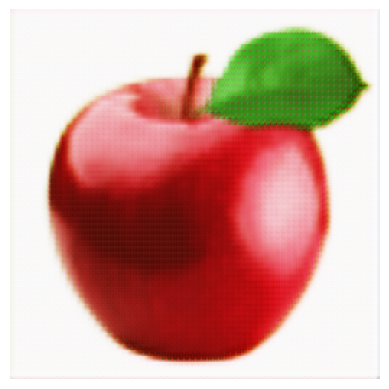

In [6]:
# 【初学者阅读说明】
# 这是 apple.ipynb 的第 8 个单元格，属于历史学习实验。
# Notebook 与 .py 不同：多个单元格共享内核变量，通常要按顺序运行前置单元格。
# 本次只增加注释，保留原实验行为和已有输出；正式项目的修正请以各包内 .py 为准。

# 推理阶段不需要梯度计算
# 禁用梯度计算，减少内存消耗并加速推理过程
# with torch.no_grad() 临时关闭梯度记录，退出块后恢复原状态；它不等同于 model.eval()。
with torch.no_grad():
    # 将图像张量移动到指定设备（GPU 或 CPU）
    # 把用于推理的图片放到模型所在设备，不会因此重新训练。
    data = img_tensor.to(device)
    # 使用训练好的模型对输入数据进行重构，得到输出张量
    # 执行当前网络或当前层的前向运算，把结果保存为下一步要使用的张量。
    recon = model(data)

# 导入 Matplotlib 库，用于图像显示
# 导入 matplotlib.pyplot，把图片张量绘制成可查看的对比图；as plt 给它起较短别名
import matplotlib.pyplot as plt

# 显示重构后的图像
# 1. 将张量从 GPU 移到 CPU（如果张量在 GPU 上）
# 2. 转换为 NumPy 数组
# 3. 调整维度顺序从 (C, H, W) 到 (H, W, C)，以适配 Matplotlib 的 imshow 函数
# 把 [H,W,C] 数组绘制在子图中；不要直接把 [C,H,W] 的 PyTorch 排列交给它。
plt.imshow(recon.cpu().numpy().transpose((1, 2, 0)))

# 关闭坐标轴显示，使图像更干净
# 设置绘图坐标轴显示；off 只隐藏坐标刻度，不改变图片像素。
plt.axis('OFF')

# 渲染并显示图像窗口
# 显示历史实验中的绘图结果；Notebook 内嵌输出或桌面窗口取决于绘图后端。
plt.show()
